# AstroMatch — Runnable Astrology-Based Recommendation System

This notebook is **self-contained**: it does not import a missing `astromatch` package. It reads `Astrology_Research.xlsx`, validates the data, optionally calculates a new user's Vedic sidereal chart, ranks eligible candidates with transparent planetary weights, and explains the scores.

**Default mode:** a clearly labelled demo profile so the notebook runs from top to bottom without stopping for input. To use your own birth details, set `USE_INTERACTIVE_INPUT = True` in Section 1.

**Important limitations:** the workbook has 64 records, but some records lack planetary placements. The available planetary columns store Rashi/sign numbers (1–12), not exact degrees. The system can compare stored signs, but it cannot reconstruct missing degrees, Nakshatras, or house placements for existing candidates. Scores represent a configurable astrology-based ranking, not scientifically validated relationship predictions.


## 1. Setup and settings

In [24]:
%pip install pandas numpy matplotlib openpyxl pyswisseph geopy

In [25]:
from pathlib import Path
from datetime import datetime, date, time, timezone
from zoneinfo import ZoneInfo
import math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import swisseph as swe
except ImportError as exc:
    raise ImportError("Swiss Ephemeris is required. Run: %pip install pyswisseph") from exc

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# Edit these settings:
DATA_FILE = "Astrology_Research.xlsx"
USE_INTERACTIVE_INPUT = True   # Changed to True to allow custom birth details
TOP_N = 5

# Planet weights are illustrative astrology-based design choices, not empirically validated.
WEIGHTS = {
    "Moon": 20, "ASC": 15, "Venus": 15, "Mars": 10, "Jupiter": 10,
    "Sun": 10, "Mercury": 8, "Saturn": 5, "Nodes": 7
}
assert abs(sum(WEIGHTS.values()) - 100) < 1e-9, "Weights must sum to 100."

RASHI_NAMES = {
    1:"Aries", 2:"Taurus", 3:"Gemini", 4:"Cancer", 5:"Leo", 6:"Virgo",
    7:"Libra", 8:"Scorpio", 9:"Sagittarius", 10:"Capricorn", 11:"Aquarius", 12:"Pisces"
}
PLANETS = ["ASC","Sun","Moon","Mars","Mercury","Jupiter","Venus","Saturn","Rahu","Ketu"]
print("Setup complete. Weights:", sum(WEIGHTS.values()), "%")

Setup complete. Weights: 100 %


## 2. Load and validate the dataset

In [26]:
# Find the workbook in the notebook folder or common mounted upload folder.
candidate_paths = [Path(DATA_FILE), Path.cwd() / DATA_FILE, Path("/mnt/data") / DATA_FILE]
workbook = next((p for p in candidate_paths if p.exists()), None)
if workbook is None:
    raise FileNotFoundError(
        f"Could not find {DATA_FILE!r}. Put the workbook next to this notebook "
        "or update DATA_FILE to its full path."
    )

df = pd.read_excel(workbook, sheet_name="Astrology_Rashi_Ank")
required = {"Name", "Date", "Time", "Place", "Gender", "Height", *PLANETS}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Workbook is missing required columns: {sorted(missing)}")

df["Name"] = df["Name"].astype("string").str.strip()
df["Date"] = pd.to_datetime(df["Date"], errors="coerce", dayfirst=False)
for col in PLANETS:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    # Accept only valid Rashi values 1-12; invalid values become missing.
    df.loc[~df[col].between(1, 12), col] = np.nan
df["Height"] = pd.to_numeric(df["Height"], errors="coerce")
df["Gender"] = pd.to_numeric(df["Gender"], errors="coerce")

# Dataset convention inferred from the existing workbook: 0 = Female, 1 = Male.
# Change this mapping if your data dictionary says otherwise.
GENDER_LABELS = {0: "Female", 1: "Male"}
df["GenderLabel"] = df["Gender"].map(GENDER_LABELS).fillna("Unknown")
df["n_features"] = df[PLANETS].notna().sum(axis=1)
df["eligible"] = df["Name"].notna() & (df["Name"].str.len() > 0) & (df["n_features"] >= 1)
df["dq_flags"] = ""
df.loc[df["n_features"] == 0, "dq_flags"] = "No planetary placements"
df.loc[df["Date"].isna(), "dq_flags"] = df.loc[df["Date"].isna(), "dq_flags"].apply(
    lambda x: (x + "; " if x else "") + "Missing/unparseable date"
)

print(f"Loaded: {workbook}")
print(f"Rows: {len(df)} | rows with at least one planetary placement: {int(df['eligible'].sum())}")
print("Rows with data-quality flags:")
display(df.loc[df["dq_flags"] != "", ["Name", "Date", "Place", "dq_flags"]])
display(df.head())


Loaded: Astrology_Research.xlsx
Rows: 64 | rows with at least one planetary placement: 58
Rows with data-quality flags:


,Name,Date,Place,dq_flags
5,Sunil Khilari,1973-01-06,"Galvewadi,Atpadi,Sangli,MS-India",No planetary placements
9,Tanvi,2016-12-14,Gulbarga Karnataka,No planetary placements
14,Abhijeet Andhale,2016-12-14,Nashik,No planetary placements
17,Jagdish Borde,2016-12-14,Buldana,No planetary placements
18,vishal wankhede,2016-12-14,"bhivapur ward, chandrapur, maharashtra, india",No planetary placements
24,Ankush,1991-12-12,Wardha,No planetary placements


,Sr. No.,Name,Date,Time,Place,ASC,Sun,Moon,Mars,Mercury,Jupiter,Venus,Saturn,Rahu,Ketu,Height,Gender,GenderLabel,n_features,eligible,dq_flags
0,1,Pallavi,1982-01-10,06:45:00,"Vegaon, Maharashtra, India",9.0,9.0,3.0,6.0,10.0,7.0,10.0,6.0,3.0,9.0,155.0,0,Female,10,True,
1,2,Ramdas Kendre,1979-09-28,17:55:00,"Udgir, Latur, Maharshtra, India",12.0,7.0,10.0,5.0,7.0,6.0,7.0,6.0,6.0,11.0,167.0,1,Male,10,True,
2,3,Yogesh R Padme,1992-06-17,07:00:00,Aurangabad (maharashtra),3.0,3.0,9.0,1.0,3.0,5.0,3.0,10.0,9.0,3.0,152.0,1,Male,10,True,
3,4,Jaideep Solanki,1978-08-12,07:15:00,"Pune, Maharashtra, India",5.0,4.0,7.0,6.0,5.0,4.0,6.0,5.0,6.0,12.0,175.0,1,Male,10,True,
4,5,Pratusha Patil,1992-04-14,10:00:00,Akola,3.0,1.0,5.0,11.0,12.0,5.0,12.0,10.0,9.0,3.0,157.5,0,Female,10,True,


## 3. Chart calculation helpers (Vedic sidereal, Lahiri)

In [27]:
def sign_from_longitude(longitude):
    """Convert ecliptic longitude to a 1-12 sign number."""
    return int(longitude % 360 // 30) + 1

def jd_from_utc(dt_utc):
    """Julian day from an aware UTC datetime."""
    dt_utc = dt_utc.astimezone(timezone.utc)
    hour = dt_utc.hour + dt_utc.minute / 60 + dt_utc.second / 3600
    return swe.julday(dt_utc.year, dt_utc.month, dt_utc.day, hour)

def calculate_chart(dob, tob, latitude, longitude, tz_name="Asia/Kolkata"):
    """Return sign placements calculated with Swiss Ephemeris, Lahiri sidereal zodiac.
    dob: date object or YYYY-MM-DD string; tob: HH:MM or time object.
    latitude/longitude are decimal degrees; timezone must be an IANA timezone.
    """
    if isinstance(dob, str):
        dob = datetime.strptime(dob, "%Y-%m-%d").date()
    if isinstance(tob, str):
        tob = datetime.strptime(tob, "%H:%M").time()
    local_dt = datetime.combine(dob, tob).replace(tzinfo=ZoneInfo(tz_name))
    utc_dt = local_dt.astimezone(timezone.utc)
    jd = jd_from_utc(utc_dt)

    swe.set_sid_mode(swe.SIDM_LAHIRI)
    flags = swe.FLG_SWIEPH | swe.FLG_SIDEREAL
    body_ids = {
        "Sun": swe.SUN, "Moon": swe.MOON, "Mars": swe.MARS, "Mercury": swe.MERCURY,
        "Jupiter": swe.JUPITER, "Venus": swe.VENUS, "Saturn": swe.SATURN,
        "Rahu": swe.MEAN_NODE
    }
    signs = {}
    longitudes = {}
    for name, body in body_ids.items():
        result, _ = swe.calc_ut(jd, body, flags)
        longitudes[name] = float(result[0] % 360)
        signs[name] = sign_from_longitude(result[0])
    # Ketu is exactly opposite the mean Rahu axis.
    longitudes["Ketu"] = (longitudes["Rahu"] + 180) % 360
    signs["Ketu"] = sign_from_longitude(longitudes["Ketu"])

    # Calculate Ascendant from the local place and UTC Julian day.
    houses, ascmc = swe.houses_ex(jd, latitude, longitude, b'P', swe.FLG_SIDEREAL)
    asc_long = float(ascmc[0] % 360)
    signs["ASC"] = sign_from_longitude(asc_long)
    longitudes["ASC"] = asc_long
    return {"signs": signs, "longitudes": longitudes, "utc_datetime": utc_dt,
            "latitude": latitude, "longitude": longitude, "timezone": tz_name}

def resolve_birthplace(place_text):
    """Geocode a place using geopy. Requires internet. Returns lat, lon, timezone.
    Timezone fallback is India Standard Time for Indian locations; for other locations
    enter coordinates/timezone manually by adapting this function if necessary.
    """
    try:
        from geopy.geocoders import Nominatim
        geolocator = Nominatim(user_agent="astromatch_student_project", timeout=8)
        loc = geolocator.geocode(place_text)
    except Exception as exc:
        raise ValueError(f"Could not geocode birthplace. Check internet/place spelling. Details: {exc}")
    if loc is None:
        raise ValueError("Birthplace could not be found. Try 'City, State, Country'.")
    # timezonefinder is optional; if unavailable, use India timezone only when location says India.
    try:
        from timezonefinder import TimezoneFinder
        tz_name = TimezoneFinder().timezone_at(lat=loc.latitude, lng=loc.longitude)
    except ImportError:
        tz_name = None
    if not tz_name:
        if any(token in place_text.lower() for token in ["india", "maharashtra", "mumbai", "pune"]):
            tz_name = "Asia/Kolkata"
        else:
            raise ValueError("Install timezonefinder for non-Indian locations: %pip install timezonefinder")
    return float(loc.latitude), float(loc.longitude), tz_name

print("Chart helpers ready. Uses sidereal Lahiri positions and mean Rahu.")


Chart helpers ready. Uses sidereal Lahiri positions and mean Rahu.


## 4. Get a user profile (interactive or demo)

In [29]:
if USE_INTERACTIVE_INPUT:
    user_name = input("Your name: ").strip() or "New User"
    dob_text = input("Date of birth (YYYY-MM-DD or DD-MM-YYYY): ").strip()
    tob_text = input("Exact local time of birth (HH:MM, 24-hour): ").strip()
    birthplace = input("Birthplace (city, state, country): ").strip()
    gender_text = input("Your gender (Female/Male/Other): ").strip().title()
    preferred_gender = input("Preferred gender for recommendations (Female/Male/Other/Any): ").strip().title()
    latitude, longitude, tz_name = resolve_birthplace(birthplace)

    # Try parsing different date formats flexibly
    dob = None
    for fmt in ("%Y-%m-%d", "%d-%m-%Y", "%Y/%m/%d", "%d/%m/%Y"):
        try:
            dob = datetime.strptime(dob_text, fmt).date()
            break
        except ValueError:
            continue
    if dob is None:
        raise ValueError(f"Could not parse date '{dob_text}'. Please use YYYY-MM-DD or DD-MM-YYYY format.")

    tob = datetime.strptime(tob_text, "%H:%M").time()
    user_chart = calculate_chart(dob, tob, latitude, longitude, tz_name)
    user_signs = user_chart["signs"].copy()
    user_gender = gender_text
    user_dob = dob
else:
    # Explicitly synthetic demo profile; default mode runs without user input or geocoding.
    user_name = "Synthetic Demo User"
    dob = date(1996, 2, 25)
    tob = time(8, 30)
    birthplace = "Pune, Maharashtra, India"
    latitude, longitude, tz_name = 18.5204, 73.8567, "Asia/Kolkata"
    user_chart = calculate_chart(dob, tob, latitude, longitude, tz_name)
    user_signs = user_chart["signs"].copy()
    user_gender = "Female"
    user_dob = dob
    preferred_gender = "Male"
    print("⚠ DEMO MODE: using an invented synthetic profile, not a real person.")

print(f"Profile: {user_name} | {dob} {tob} | {birthplace}")
chart_table = pd.DataFrame([
    {"Point": p, "Rashi number": user_signs[p], "Sign": RASHI_NAMES[user_signs[p]],
     "Longitude (sidereal)": round(user_chart["longitudes"][p], 2)}
    for p in ["ASC", "Sun", "Moon", "Mars", "Mercury", "Jupiter", "Venus", "Saturn", "Rahu", "Ketu"]
])
display(chart_table)

Your name: shriy
Date of birth (YYYY-MM-DD or DD-MM-YYYY): 16-06-2005
Exact local time of birth (HH:MM, 24-hour): 23:34
Birthplace (city, state, country): mumbai, maharashtra, india
Your gender (Female/Male/Other): female
Preferred gender for recommendations (Female/Male/Other/Any): male
Profile: shriy | 2005-06-16 23:34:00 | mumbai, maharashtra, india


,Point,Rashi number,Sign,Longitude (sidereal)
0,ASC,11,Aquarius,309.55
1,Sun,3,Gemini,61.75
2,Moon,6,Virgo,171.27
3,Mars,12,Pisces,339.29
4,Mercury,3,Gemini,76.95
5,Jupiter,6,Virgo,165.20
6,Venus,3,Gemini,82.08
7,Saturn,4,Cancer,92.36
8,Rahu,12,Pisces,355.56
9,Ketu,6,Virgo,175.56


## 5. Compatibility scoring and recommendation logic

In [30]:
def normalize_weights(weights):
    weights = {k: float(v) for k, v in weights.items() if float(v) > 0}
    total = sum(weights.values())
    if total <= 0:
        raise ValueError("At least one weight must be positive.")
    return {k: v / total for k, v in weights.items()}

def sign_harmony(a, b):
    """Transparent circular sign-distance score: 100 for same sign, 0 for opposite signs."""
    if pd.isna(a) or pd.isna(b):
        return np.nan
    distance = abs(int(a) - int(b))
    distance = min(distance, 12 - distance)
    return 100.0 * (1 - distance / 6)

def candidate_signs(row):
    s = {p: row[p] for p in PLANETS}
    # Combine Rahu/Ketu as one axis to avoid counting the same axis twice.
    return s

def score_candidate(user_signs, row, weights):
    w = normalize_weights(weights)
    scores = {}
    for feature in w:
        if feature == "Nodes":
            pairs = [("Rahu", "Rahu"), ("Ketu", "Ketu")]
            vals = [sign_harmony(user_signs[a], row[b]) for a, b in pairs]
            vals = [v for v in vals if not pd.isna(v)]
            scores[feature] = float(np.mean(vals)) if vals else np.nan
        else:
            scores[feature] = sign_harmony(user_signs[feature], row[feature])
    available = {k: v for k, v in scores.items() if not pd.isna(v)}
    if not available:
        return np.nan, scores, {}
    effective_total = sum(w[k] for k in available)
    normalized = {k: w[k] / effective_total for k in available}
    contributions = {k: scores[k] * normalized[k] for k in available}
    final_score = float(sum(contributions.values()))
    return round(final_score, 2), scores, contributions

def recommend(user_name, user_gender, preferred_gender, user_dob, user_signs, data, weights, top_n=5,
              min_age=None, max_age=None, min_height=None, max_height=None):
    pool = data[data["eligible"]].copy()
    pool = pool[pool["Name"].str.casefold() != user_name.strip().casefold()]
    if preferred_gender and preferred_gender.lower() != "any":
        pool = pool[pool["GenderLabel"].str.casefold() == preferred_gender.casefold()]
    if user_dob is not None and "Date" in pool:
        pool["Age"] = ((pd.Timestamp.today().normalize() - pool["Date"]).dt.days / 365.2425).round(1)
        pool.loc[pool["Date"].isna(), "Age"] = np.nan
        # Dating recommendations are restricted to adults with a parseable DOB.
        pool = pool[pool["Age"].notna() & (pool["Age"] >= 18)]
        if min_age is not None:
            pool = pool[pool["Age"] >= min_age]
        if max_age is not None:
            pool = pool[pool["Age"] <= max_age]
    else:
        pool["Age"] = np.nan

    if min_height is not None:
        pool = pool[pool["Height"].isna() | (pool["Height"] >= min_height)]
    if max_height is not None:
        pool = pool[pool["Height"].isna() | (pool["Height"] <= max_height)]

    output, details = [], {}
    for _, row in pool.iterrows():
        score, feature_scores, contributions = score_candidate(user_signs, row, weights)
        if pd.isna(score):
            continue
        output.append({
            "Name": row["Name"], "Gender": row["GenderLabel"], "Age": row["Age"],
            "Height (cm)": row["Height"], "Score": score,
            "Available features": len(feature_scores) - sum(pd.isna(v) for v in feature_scores.values())
        })
        details[row["Name"]] = {"scores": feature_scores, "contributions": contributions, "row": row}
    results = pd.DataFrame(output)
    if results.empty:
        return results, details
    results = results.sort_values(["Score", "Name"], ascending=[False, True]).head(top_n).reset_index(drop=True)
    results.insert(0, "Rank", np.arange(1, len(results) + 1))
    return results, details

print("Scoring engine ready. Effective weights are renormalized if a feature is missing.")


Scoring engine ready. Effective weights are renormalized if a feature is missing.


## 6. Generate ranked recommendations

In [31]:
# Optional filters: set a number to activate a filter, or leave as None.
MIN_AGE = None
MAX_AGE = None
MIN_HEIGHT_CM = None
MAX_HEIGHT_CM = None

ranked, detail_map = recommend(
    user_name=user_name, user_gender=user_gender, preferred_gender=preferred_gender,
    user_dob=user_dob, user_signs=user_signs, data=df, weights=WEIGHTS, top_n=TOP_N,
    min_age=MIN_AGE, max_age=MAX_AGE, min_height=MIN_HEIGHT_CM, max_height=MAX_HEIGHT_CM
)

if ranked.empty:
    print("No eligible candidates matched the current filters. Try preferred_gender='Any' or relax filters.")
else:
    display(ranked)


,Rank,Name,Gender,Age,Height (cm),Score,Available features
0,1,Damodar,Male,34.2,178.0,69.33,9
1,2,Yogesh R Padme,Male,34.4,152.0,68.17,9
2,3,Mahesh,Male,43.5,170.0,66.00,9
3,4,Ashish Patole,Male,36.5,178.0,65.83,9
4,5,Kapil Chawla,Male,33.4,177.4,64.00,9


## 7. Explain each recommendation

In [32]:
if ranked.empty:
    print("No recommendations to explain.")
else:
    for _, result in ranked.iterrows():
        name = result["Name"]
        info = detail_map[name]
        print(f"\n#{int(result['Rank'])} {name} — {result['Score']:.2f}/100")
        print("This score is an astrology-based ranking, not a probability of relationship success.")
        rows = []
        for feature in WEIGHTS:
            value = info["scores"].get(feature, np.nan)
            contribution = info["contributions"].get(feature, np.nan)
            rows.append({
                "Feature": feature,
                "Weight (%)": WEIGHTS[feature],
                "Compatibility score (0–100)": round(value, 2) if not pd.isna(value) else "Unavailable",
                "Weighted contribution": round(contribution, 2) if not pd.isna(contribution) else "Excluded"
            })
        display(pd.DataFrame(rows))
        strongest = sorted(
            [(k, v) for k, v in info["scores"].items() if not pd.isna(v)],
            key=lambda kv: kv[1], reverse=True
        )
        weakest = list(reversed(strongest))
        if strongest:
            print("Strongest factors:", ", ".join(f"{k} ({v:.0f}/100)" for k, v in strongest[:3]))
            print("Lowest factors:", ", ".join(f"{k} ({v:.0f}/100)" for k, v in weakest[:2]))
        print("Method: same-planet Rashi signs compared using circular sign distance; missing features are excluded and remaining weights renormalized.")



#1 Damodar — 69.33/100
This score is an astrology-based ranking, not a probability of relationship success.


,Feature,Weight (%),Compatibility score (0–100),Weighted contribution
0,Moon,20,66.67,13.33
1,ASC,15,83.33,12.50
2,Venus,15,66.67,10.00
3,Mars,10,66.67,6.67
4,Jupiter,10,83.33,8.33
5,Sun,10,83.33,8.33
6,Mercury,8,83.33,6.67
7,Saturn,5,0.00,0.00
8,Nodes,7,50.00,3.50


Strongest factors: ASC (83/100), Jupiter (83/100), Sun (83/100)
Lowest factors: Saturn (0/100), Nodes (50/100)
Method: same-planet Rashi signs compared using circular sign distance; missing features are excluded and remaining weights renormalized.

#2 Yogesh R Padme — 68.17/100
This score is an astrology-based ranking, not a probability of relationship success.


,Feature,Weight (%),Compatibility score (0–100),Weighted contribution
0,Moon,20,50.00,10.00
1,ASC,15,33.33,5.00
2,Venus,15,100.00,15.00
3,Mars,10,83.33,8.33
4,Jupiter,10,83.33,8.33
5,Sun,10,100.00,10.00
6,Mercury,8,100.00,8.00
7,Saturn,5,0.00,0.00
8,Nodes,7,50.00,3.50


Strongest factors: Venus (100/100), Sun (100/100), Mercury (100/100)
Lowest factors: Saturn (0/100), ASC (33/100)
Method: same-planet Rashi signs compared using circular sign distance; missing features are excluded and remaining weights renormalized.

#3 Mahesh — 66.00/100
This score is an astrology-based ranking, not a probability of relationship success.


...

Strongest factors: Moon (83/100), Venus (83/100), Mars (83/100)
Lowest factors: ASC (17/100), Nodes (50/100)
Method: same-planet Rashi signs compared using circular sign distance; missing features are excluded and remaining weights renormalized.

#4 Ashish Patole — 65.83/100
This score is an astrology-based ranking, not a probability of relationship success.


,Feature,Weight (%),Compatibility score (0–100),Weighted contribution
0,Moon,20,66.67,13.33
1,ASC,15,100.00,15.00
2,Venus,15,50.00,7.50
3,Mars,10,83.33,8.33
4,Jupiter,10,50.00,5.00
5,Sun,10,66.67,6.67
6,Mercury,8,66.67,5.33
7,Saturn,5,0.00,0.00
8,Nodes,7,66.67,4.67


Strongest factors: ASC (100/100), Mars (83/100), Moon (67/100)
Lowest factors: Saturn (0/100), Jupiter (50/100)
Method: same-planet Rashi signs compared using circular sign distance; missing features are excluded and remaining weights renormalized.

#5 Kapil Chawla — 64.00/100
This score is an astrology-based ranking, not a probability of relationship success.


,Feature,Weight (%),Compatibility score (0–100),Weighted contribution
0,Moon,20,50.00,10.00
1,ASC,15,100.00,15.00
2,Venus,15,50.00,7.50
3,Mars,10,33.33,3.33
4,Jupiter,10,100.00,10.00
5,Sun,10,83.33,8.33
6,Mercury,8,83.33,6.67
7,Saturn,5,16.67,0.83
8,Nodes,7,33.33,2.33


Strongest factors: ASC (100/100), Jupiter (100/100), Sun (83/100)
Lowest factors: Saturn (17/100), Nodes (33/100)
Method: same-planet Rashi signs compared using circular sign distance; missing features are excluded and remaining weights renormalized.


## 8. Visualize the top recommendations

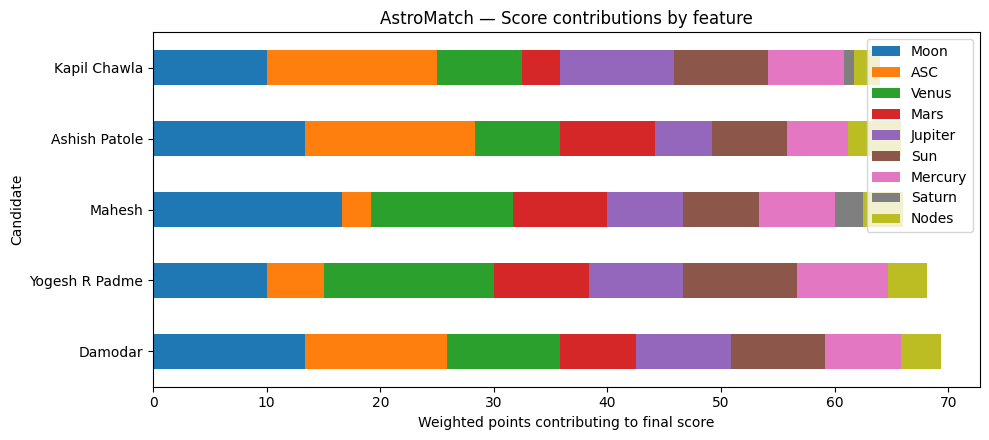

In [33]:
if not ranked.empty:
    contribution_data = {}
    for name in ranked["Name"]:
        contribution_data[name] = detail_map[name]["contributions"]
    contribution_df = pd.DataFrame(contribution_data).T.fillna(0)
    # Convert each weighted feature contribution to points on the 0-100 score scale.
    ax = contribution_df.plot(kind="barh", stacked=True, figsize=(10, max(3, 0.7 * len(contribution_df) + 1)))
    ax.set_xlabel("Weighted points contributing to final score")
    ax.set_ylabel("Candidate")
    ax.set_title("AstroMatch — Score contributions by feature")
    plt.tight_layout()
    plt.show()
else:
    print("No chart to display because there are no recommendations.")


## 9. Baseline comparison and sanity checks

In [34]:
# Simple baseline: compare only the user's and candidate's Sun signs.
baseline_rows = []
sun_weight_only = {"Sun": 100}
baseline, _ = recommend(
    user_name=user_name, user_gender=user_gender, preferred_gender=preferred_gender,
    user_dob=user_dob, user_signs=user_signs, data=df, weights=sun_weight_only, top_n=TOP_N
)
if not ranked.empty:
    enhanced_compare = ranked[["Rank", "Name", "Score"]].rename(
        columns={"Rank": "Enhanced rank", "Score": "Enhanced score"}
    )
    if not baseline.empty:
        baseline_compare = baseline[["Rank", "Name", "Score"]].rename(
            columns={"Rank": "Sun-only rank", "Score": "Sun-only score"}
        )
        comparison = enhanced_compare.merge(baseline_compare, on="Name", how="outer")
        display(comparison.sort_values("Enhanced rank", na_position="last"))
    else:
        display(enhanced_compare)
else:
    print("No enhanced results available for comparison.")

# Basic assertions: weights normalize, harmony is bounded, same sign scores highest.
assert abs(sum(normalize_weights(WEIGHTS).values()) - 1) < 1e-9
assert sign_harmony(1, 1) == 100
assert sign_harmony(1, 7) == 0
assert 0 <= sign_harmony(1, 12) <= 100
print("Sanity checks passed.")


,Enhanced rank,Name,Enhanced score,Sun-only rank,Sun-only score
5,1.0,Damodar,69.33,NaN,NaN
8,2.0,Yogesh R Padme,68.17,2.0,100.00
7,3.0,Mahesh,66.00,NaN,NaN
2,4.0,Ashish Patole,65.83,NaN,NaN
6,5.0,Kapil Chawla,64.00,NaN,NaN
0,NaN,Abhishek Mishra,NaN,3.0,83.33
1,NaN,Akshay Dawada,NaN,4.0,83.33
3,NaN,Chaitanya Vikas Deshpande,NaN,1.0,100.00
4,NaN,DHIRAJ,NaN,5.0,83.33


Sanity checks passed.


## 11. Run AstroMatch Interactively (Calculate Your Top Recommendations)
Run the cell below to input your birth details and compute your personalized top astrology-based recommendations!

In [35]:
# Interactive input gathering and recommendation calculator with flexible date parsing
try:
    # Prompt user for inputs
    user_name = input("Enter your name: ").strip() or "User"
    dob_text = input("Enter Date of Birth (e.g. YYYY-MM-DD or DD-MM-YYYY): ").strip()
    tob_text = input("Enter Local Time of Birth (HH:MM in 24-hour format): ").strip()
    birthplace = input("Enter Birthplace (City, State, Country): ").strip()
    gender_text = input("Your Gender (Female/Male/Other): ").strip().title()
    preferred_gender = input("Preferred Gender for recommendations (Female/Male/Other/Any): ").strip().title()

    print("\nGeocoding birthplace and calculating your sidereal Vedic chart...")
    latitude, longitude, tz_name = resolve_birthplace(birthplace)

    # Try parsing different date formats flexibly
    dob = None
    for fmt in ("%Y-%m-%d", "%d-%m-%Y", "%Y/%m/%d", "%d/%m/%Y"):
        try:
            dob = datetime.strptime(dob_text, fmt).date()
            break
        except ValueError:
            continue
    if dob is None:
        raise ValueError(f"Could not parse date '{dob_text}'. Please use YYYY-MM-DD or DD-MM-YYYY format.")

    tob = datetime.strptime(tob_text, "%H:%M").time()

    # Calculate user's chart
    user_chart = calculate_chart(dob, tob, latitude, longitude, tz_name)
    user_signs = user_chart["signs"].copy()

    print(f"\n--- Profile: {user_name} (Gender: {gender_text}) ---")
    chart_table = pd.DataFrame([
        {"Point": p, "Rashi": RASHI_NAMES[user_signs[p]], "Rashi Number": user_signs[p]}
        for p in PLANETS
    ])
    display(chart_table)

    # Generate matches
    ranked, detail_map = recommend(
        user_name=user_name, user_gender=gender_text, preferred_gender=preferred_gender,
        user_dob=dob, user_signs=user_signs, data=df, weights=WEIGHTS, top_n=TOP_N
    )

    if ranked.empty:
        print("\nNo matching candidates found with current filters. Try setting Preferred Gender to 'Any'.")
    else:
        print(f"\n--- Top {TOP_N} Compatibility Recommendations for {user_name} ---")
        display(ranked)

        # Explain the matches
        print("\n--- Detailed Breakdown of Top Recommendations ---")
        for _, result in ranked.iterrows():
            name = result["Name"]
            info = detail_map[name]
            print(f"\n#{int(result['Rank'])} {name} — Score: {result['Score']:.2f}/100")
            strongest = sorted(
                [(k, v) for k, v in info["scores"].items() if not pd.isna(v)],
                key=lambda kv: kv[1], reverse=True
            )
            weakest = list(reversed(strongest))
            if strongest:
                print("  Strongest factors:", ", ".join(f"{k} ({v:.0f}/100)" for k, v in strongest[:3]))
                print("  Lowest factors:", ", ".join(f"{k} ({v:.0f}/100)" for k, v in weakest[:2]))
except Exception as e:
    print(f"An error occurred: {e}. Please ensure your formats are correct and you are connected to the internet for geocoding.")

Enter your name: shriya
Enter Date of Birth (e.g. YYYY-MM-DD or DD-MM-YYYY): 16-06-2005
Enter Local Time of Birth (HH:MM in 24-hour format): 23:34
Enter Birthplace (City, State, Country): mumbai, maharashtra, india
Your Gender (Female/Male/Other): female
Preferred Gender for recommendations (Female/Male/Other/Any): male

Geocoding birthplace and calculating your sidereal Vedic chart...

--- Profile: shriya (Gender: Female) ---


,Point,Rashi,Rashi Number
0,ASC,Aquarius,11
1,Sun,Gemini,3
2,Moon,Virgo,6
3,Mars,Pisces,12
4,Mercury,Gemini,3
5,Jupiter,Virgo,6
6,Venus,Gemini,3
7,Saturn,Cancer,4
8,Rahu,Pisces,12
9,Ketu,Virgo,6



--- Top 5 Compatibility Recommendations for shriya ---


,Rank,Name,Gender,Age,Height (cm),Score,Available features
0,1,Damodar,Male,34.2,178.0,69.33,9
1,2,Yogesh R Padme,Male,34.4,152.0,68.17,9
2,3,Mahesh,Male,43.5,170.0,66.00,9
3,4,Ashish Patole,Male,36.5,178.0,65.83,9
4,5,Kapil Chawla,Male,33.4,177.4,64.00,9



--- Detailed Breakdown of Top Recommendations ---

#1 Damodar — Score: 69.33/100
  Strongest factors: ASC (83/100), Jupiter (83/100), Sun (83/100)
  Lowest factors: Saturn (0/100), Nodes (50/100)

#2 Yogesh R Padme — Score: 68.17/100
  Strongest factors: Venus (100/100), Sun (100/100), Mercury (100/100)
  Lowest factors: Saturn (0/100), ASC (33/100)

#3 Mahesh — Score: 66.00/100
  Strongest factors: Moon (83/100), Venus (83/100), Mars (83/100)
  Lowest factors: ASC (17/100), Nodes (50/100)

#4 Ashish Patole — Score: 65.83/100
  Strongest factors: ASC (100/100), Mars (83/100), Moon (67/100)
  Lowest factors: Saturn (0/100), Jupiter (50/100)

#5 Kapil Chawla — Score: 64.00/100
  Strongest factors: ASC (100/100), Jupiter (100/100), Sun (83/100)
  Lowest factors: Saturn (17/100), Nodes (33/100)


## 10. Methodology and limitations

- **Recommendation type:** content-based, cold-start ranking. The user provides chart features; candidates are ranked using available planetary sign placements.
- **Why no trained ML model?** The workbook contains profiles but no likes, mutual matches, ratings, or relationship outcomes. There is no valid target label for training or evaluating real-world compatibility.
- **Weights:** configurable illustrative assumptions, not empirically learned or scientifically validated.
- **Planetary data:** the dataset provides sign numbers rather than exact degrees. The user's chart can be calculated from birth data, but existing candidates' missing or incomplete charts cannot be reconstructed reliably from signs alone.
- **Astrological convention:** this notebook uses Lahiri sidereal signs, mean Rahu and Ketu opposite Rahu for the newly calculated chart. Verify that this matches your data's provenance.
- **Geocoding:** interactive mode uses online geocoding. If your environment has no internet, replace the geocoding helper with known coordinates and timezone for your birthplace.
- **Gender encoding:** the workbook is treated as `0 = Female`, `1 = Male`; change `GENDER_LABELS` if that assumption is incorrect.
- **Responsible interpretation:** scores summarize the selected rules. They do not establish personality, relationship quality, or future success.
